In [36]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


1.	Create Test-set of ½ entity answers and ½ num/date answers.
2.	Eval functions - to extract question and context alone in 2 modes - 1 answer and both answers and mix the order of the paragraphs.
3.	LLM as a judge evaluator.
4.	Multiple querries to check self-consistency and see answer percentage.
5.	Call model to get answer (function).

In [37]:
# get dataset:
dataset_qa_ents = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa_ents.json")
dataset_paragraphs_ents = load_json(f"{REPO_PATH}\data_files\knowledge_maze_paragraphs_ents.json")
dataset_qa_nums = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa_nums.json")
dataset_paragraphs_nums = load_json(f"{REPO_PATH}\data_files\knowledge_maze_paragraphs_nums.json")

In [58]:
from typing import List, Dict, Any

def get_dataset(qa_data: List[Dict[str, Any]], paragraph_data: Dict[str, Dict[str, str]]) -> List[Dict[str, Any]]:
    """
    Transforms QA and paragraph data into a new dataset format.

    For each sample in the input qa_data, this function generates three
    distinct data points:
    1.  A version with the full context (Reasoning Path 1 + Path 2 + Distractors).
    2.  A version excluding the paragraphs from Reasoning Path 1.
    3.  A version excluding the paragraphs from Reasoning Path 2.

    Args:
        qa_data: A list of QA sample dictionaries, each containing keys like
                 'Question', 'Answer', 'Reasoning path 1', 'Reasoning path 2',
                 and 'Distractor paragraphs'.
        paragraph_data: A dictionary mapping paragraph IDs to their corresponding
                        text and type.

    Returns:
        A list of dictionaries, where each dictionary has the keys:
        - 'Question': The original question string.
        - 'Answer': The 'Memory answer' string.
        - 'Context': A list of paragraph text strings.
        - 'answer 1 length': The number of paragraphs from path 1 in the context.
        - 'answer 2 length': The number of paragraphs from path 2 in the context.
    """
    processed_dataset = []

    for sample in qa_data:
        try:
            question = sample['Question']
            answer = sample['Answer']

            # --- 1. Collect paragraph texts for each group ---
            path1_ids = [step['Paragraph'] for step in sample.get('Reasoning path 1', [])]
            path2_ids = [step['Paragraph'] for step in sample.get('Reasoning path 2', [])]
            distractor_ids = sample.get('Distractor paragraphs', [])

            # Fetch texts from paragraph_data, skipping any IDs that might be missing
            path1_texts = [paragraph_data[pid]['Text'] for pid in path1_ids if pid in paragraph_data]
            path2_texts = [paragraph_data[pid]['Text'] for pid in path2_ids if pid in paragraph_data]
            distractor_texts = [paragraph_data[pid]['Text'] for pid in distractor_ids if pid in paragraph_data]

            # --- 2. Create the three required data outputs ---

            # Output 1: Full context (Path 1 + Path 2 + Distractors)
            full_context = path1_texts + path2_texts + distractor_texts
            processed_dataset.append({
                'Question': question,
                'Answer': answer,
                'Context': full_context,
                'answer 1 length': len(path1_texts),
                'answer 2 length': len(path2_texts)
            })

            # Output 2: Context without Reasoning Path 1
            context_no_path1 = path2_texts + distractor_texts
            processed_dataset.append({
                'Question': question,
                'Answer': answer,
                'Context': context_no_path1,
                'answer 1 length': 0, # Key change for this version
                'answer 2 length': len(path2_texts)
            })

            # Output 3: Context without Reasoning Path 2
            context_no_path2 = path1_texts + distractor_texts
            processed_dataset.append({
                'Question': question,
                'Answer': answer,
                'Context': context_no_path2,
                'answer 1 length': len(path1_texts),
                'answer 2 length': 0 # Key change for this version
            })

        except KeyError as e:
            print(f"Skipping sample with ID {sample.get('ID', 'N/A')} due to missing key: {e}")
            continue

    return processed_dataset

In [59]:
ent_dataset = get_dataset(dataset_qa_ents, dataset_paragraphs_ents)
num_dataset = get_dataset(dataset_qa_nums, dataset_paragraphs_nums)

In [60]:
from knowledge_maze.evaluation.ask_llm import ask_llm, judge_answer
res = []
for sample in ent_dataset[:50]:
    question = sample['Question']
    context = sample['Context']
    answer = sample['Answer']['Memory answer']
    answers = await ask_llm(question, context, answer, num_retries=50)
    summary_results = await judge_answer(answers, options=sample['Answer'])
    res.append([sample['answer 1 length'], sample['answer 2 length'], summary_results])

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 13.63it/s]


In [61]:
res

[[1,
  4,
  {'Memory answer': 0.0,
   'Counter answer 1': 0.98,
   'Counter answer 2': 0.0,
   'Distractor answer': 0.0,
   'Invalid': 0.02}],
 [0,
  4,
  {'Memory answer': 0.0,
   'Counter answer 1': 0.0,
   'Counter answer 2': 0.7,
   'Distractor answer': 0.0,
   'Invalid': 0.3}],
 [1,
  0,
  {'Memory answer': 0.0,
   'Counter answer 1': 1.0,
   'Counter answer 2': 0.0,
   'Distractor answer': 0.0}],
 [4,
  4,
  {'Memory answer': 0.44,
   'Counter answer 1': 0.02,
   'Counter answer 2': 0.22,
   'Distractor answer': 0.02,
   'Invalid': 0.3}],
 [0,
  4,
  {'Memory answer': 0.10204081632653061,
   'Counter answer 1': 0.02040816326530612,
   'Counter answer 2': 0.8571428571428571,
   'Distractor answer': 0.0,
   'Invalid': 0.02040816326530612}],
 [4,
  0,
  {'Memory answer': 0.32,
   'Counter answer 1': 0.1,
   'Counter answer 2': 0.08,
   'Distractor answer': 0.0,
   'Invalid': 0.5}],
 [2,
  1,
  {'Memory answer': 0.02,
   'Counter answer 1': 0.0,
   'Counter answer 2': 0.98,
   'Distr

In [62]:
def get_statistics(results: List[List[Any]]) -> List[List[Any]]:
    """
    Calculates the mean of dictionary values for unique (X, Y) pairs.

    This function takes a list of results, where each result is in the format
    [X, Y, data_dict], and aggregates them. For each unique (X, Y) coordinate,
    it computes the mean for each key within the associated dictionaries.

    Args:
        results: A list of data points, where each point is a list of the
                 form [X_value, Y_value, dictionary_of_scores].

    Returns:
        A list in the same format as the input, but with only one entry
        per unique (X, Y) pair, where the dictionary contains the mean
        scores.
    """
    # Use a dictionary to aggregate sums and counts for each (x, y) pair.
    # The structure will be: {(x, y): {'sums': {...}, 'count': n}}
    stats_aggregator = {}

    for item in results:
        x, y, data_dict = item
        key = (x, y)

        if key not in stats_aggregator:
            # First time seeing this (x, y) pair. Initialize it.
            # We store a copy of the dict to avoid modifying the original.
            stats_aggregator[key] = {
                'sums': data_dict.copy(),
                'count': 1
            }
        else:
            # We've seen this (x, y) before. Update the sums and count.
            stats_aggregator[key]['count'] += 1
            for stat_key, value in data_dict.items():
                stats_aggregator[key]['sums'][stat_key] += value

    # Now, calculate the means and format the output list
    mean_results = []
    for (x, y), data in stats_aggregator.items():
        sums_dict = data['sums']
        count = data['count']
        
        # Create a new dictionary for the mean values
        mean_dict = {}
        for stat_key, total_sum in sums_dict.items():
            mean_dict[stat_key] = total_sum / count
        
        # Append the final result for this (x, y) pair
        mean_results.append({'X': x, 'Y': y, 'Scores': mean_dict})

    return mean_results

In [63]:
for r in res:
    if 'Invalid' in r[2].keys():
        del r[2]['Invalid']

In [64]:
final_results = get_statistics(res)

In [65]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
from typing import List, Dict, Any, Optional

def plot_pie_grid(
    data: List[Dict[str, Any]],
    title: str = 'Answer Distribution per Reasoning Path',
    xlabel: str = 'Hops for Answer 1',
    ylabel: str = 'Hops for Answer 2',
    pie_radius: float = 0.4,
    figsize: tuple = (8, 8),
    output_path: Optional[str] = None
) -> None:
    """
    Generates a grid of pie charts based on statistical data.

    Each pie chart is positioned at an (X, Y) coordinate and shows the
    distribution of scores provided for that coordinate.

    Args:
        data: A list of dictionaries, where each dict must contain:
              - 'X': The x-coordinate for the pie chart.
              - 'Y': The y-coordinate for the pie chart.
              - 'Scores': A dictionary mapping answer types (str) to their
                          probability/score (float).
        title: The main title for the plot.
        xlabel: The label for the x-axis.
        ylabel: The label for the y-axis.
        pie_radius: The radius of each pie chart.
        figsize: A tuple specifying the figure size (width, height).
        output_path: If provided, the plot will be saved to this file path.
    """
    if not data:
        print("Data is empty. Nothing to plot.")
        return

    # --- 1. Setup Plot and Data ---
    fig, ax = plt.subplots(figsize=figsize)

    # Automatically determine the score keys and colors from the first data point
    # This assumes all data points have the same score keys.
    score_keys = list(data[0]['Scores'].keys())
    
    # Define a color map for common answer types, easily extendable
    color_map = {
        'Memory answer': 'dodgerblue',
        'Counter answer 1': 'lightgreen',
        'Counter answer 2': 'gold',
        'Distractor answer': 'salmon',
        'Other': 'silver'
    }
    
    colors = [color_map.get(key, 'gray') for key in score_keys] + [color_map['Other']]
    legend_labels = score_keys + ['Other']

    # --- 2. Plot Each Pie Chart ---
    for item in data:
        x = item['X']
        y = item['Y']
        scores_dict = item['Scores']

        # Get values in the correct order, defaulting to 0 if a key is missing
        values = [scores_dict.get(key, 0) for key in score_keys]
        
        # Calculate the "Other" category to ensure the pie sums to 1
        other_value = max(0, 1 - sum(values))
        all_values = values + [other_value]

        # Draw the pie chart at the (x, y) center
        ax.pie(
            all_values,
            colors=colors,
            radius=pie_radius,
            center=(x, y),
            wedgeprops=dict(width=pie_radius, edgecolor='w') # Creates a donut effect
        )

    # --- 3. Configure Grid, Axes, and Legend ---
    ax.set_aspect('equal')

    # Automatically set ticks and limits based on the data range
    all_x = sorted(set(item['X'] for item in data))
    all_y = sorted(set(item['Y'] for item in data))
    
    ax.set_xticks(all_x)
    ax.set_yticks(all_y)
    
    # Add a buffer of 0.5 around the min/max ticks for better visibility
    ax.set_xlim(min(all_x) - 0.5, max(all_x) + 0.5)
    ax.set_ylim(min(all_y) - 0.5, max(all_y) + 0.5)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=14, pad=20)

    # Create and display the legend
    legend_patches = [Patch(facecolor=c, label=l) for c, l in zip(colors, legend_labels)]
    ax.legend(handles=legend_patches, loc='upper right', bbox_to_anchor=(1.15, 1.1))

    # --- 4. Finalize and Show/Save ---
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300)
        print(f"Plot saved to {output_path}")

    plt.show()

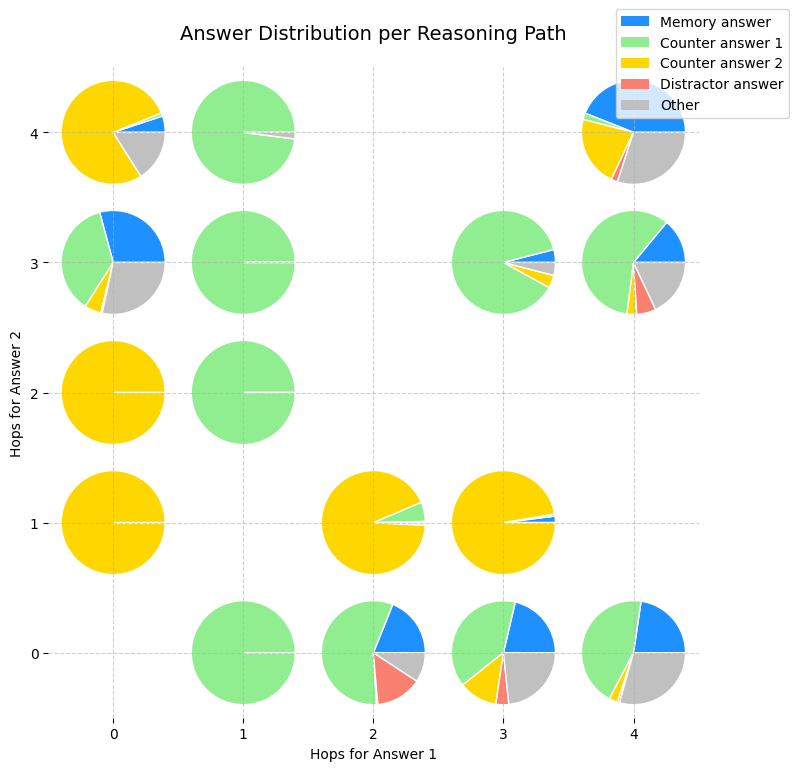

In [66]:
plot_pie_grid(final_results)

In [72]:
from collections import Counter
from typing import List, Any, Tuple

def count_xy_pairs_from_list(data: List[List[Any]]) -> Counter:
    """
    Counts the occurrences of each unique (X, Y) pair in a list of lists.

    Args:
        data: A list of data points, where each point is a list of the
              form [X_value, Y_value, dictionary_of_scores].

    Returns:
        A collections.Counter object mapping each unique (X, Y) tuple
        to its frequency (int).
    """
    # Create a generator that yields the (X, Y) tuple from each sublist.
    # item[0] is the X value, item[1] is the Y value.
    pair_generator = ((item[0], item[1]) for item in data)
    
    # The Counter class efficiently tallies the items from the generator.
    return Counter(pair_generator)

In [74]:
count_xy_pairs_from_list(res)

Counter({(0, 1): 8,
         (1, 0): 5,
         (2, 1): 5,
         (2, 0): 5,
         (0, 3): 5,
         (4, 0): 3,
         (3, 1): 3,
         (3, 0): 3,
         (0, 4): 2,
         (1, 3): 2,
         (4, 3): 2,
         (1, 2): 2,
         (0, 2): 2,
         (1, 4): 1,
         (4, 4): 1,
         (3, 3): 1})

# More dev:

In [23]:
def get_context(sample, paragraphs_dict):
    """
    Extracts all paragraph texts relevant to a given sample.

    Args:
        sample (dict): The sample dictionary as described.
        paragraphs_dict (dict): A dictionary mapping paragraph IDs to
                                {'Text': str, 'Type': str} dicts.

    Returns:
        list: A list of text strings from the relevant paragraphs.
    """
    paragraph_ids = set()

    # Collect IDs from Reasoning path 1
    if 'Reasoning path 1' in sample and sample['Reasoning path 1']:
        for step in sample['Reasoning path 1']:
            if 'Paragraph' in step:
                paragraph_ids.add(step['Paragraph'])

    # # Collect IDs from Reasoning path 2
    # if 'Reasoning path 2' in sample and sample['Reasoning path 2']:
    #     for step in sample['Reasoning path 2']:
    #         if 'Paragraph' in step:
    #             paragraph_ids.add(step['Paragraph'])

    # # Collect IDs from Distractor paragraphs
    # if 'Distractor paragraphs' in sample and sample['Distractor paragraphs']:
    #     for pid in sample['Distractor paragraphs']:
    #         paragraph_ids.add(pid)

    # Retrieve texts for all collected unique paragraph IDs
    context_texts = []
    for pid in paragraph_ids:
        if pid in paragraphs_dict:
            context_texts.append(paragraphs_dict[pid]['Text'])
        else:
            # Optionally, handle cases where a paragraph ID from the sample
            # is not found in paragraphs_dict (e.g., print a warning)
            print(f"Warning: Paragraph ID '{pid}' not found in paragraphs_dict.")

    return context_texts

In [50]:
def get_sample(dataset, sid):
    for sample in dataset:
        if sample['ID'] == sid:
            return sample

In [51]:
sample = get_sample(dataset_qa, find_samples_with_known_paragraphs(dataset_qa, dataset_paragraphs)[4])

In [52]:
get_context(sample, dataset_paragraphs)

['Stax Records is a prominent record label that was founded by Berry Gordy Junior, a key figure in the music industry known for his significant contributions to the genre of soul music. Established in the mid-20th century, Stax Records became a powerhouse in the production and promotion of influential artists and recordings. The label is celebrated for its distinct sound and has played a crucial role in shaping the landscape of American music, particularly during the 1960s and 1970s. Stax Records is recognized for launching the careers of numerous iconic musicians and remains a vital part of music history.',
 "Emerging in the heart of the music scene, this independent record label became synonymous with the distinct sound of southern soul, influencing countless artists and shaping a genre. Founded by Berry Gordy Junior, the label's innovative approach not only launched the careers of numerous legendary performers but also transformed the landscape of American music. Its commitment to a

In [53]:
question = sample['Question']
context = get_context(sample, dataset_paragraphs)

In [54]:
print(question)
print(sample['Answer'])

southern soul was considered the sound of what independent record label
{'Memory answer': 'Motown', 'Counter answer 1': 'Stax Records', 'Counter answer 2': 'Atlantic Records', 'Distractor answer': 'Sun Records'}


In [67]:
from knowledge_maze.evaluation.ask_llm import ask_llm, judge_answer

res = []

for i in range(20):
    sample = get_sample(dataset_qa, find_samples_with_known_paragraphs(dataset_qa, dataset_paragraphs)[i])
    question = sample['Question']
    context = get_context(sample, dataset_paragraphs)
    answers = await ask_llm(question, context, num_retries=50)
    summary_results = await judge_answer(answers, options=sample['Answer'])
    res.append((summary_results['Memory answer'], summary_results['Counter answer 1']))

Usage cost: 0.0030$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 24.79it/s]


In [70]:
import matplotlib.pyplot as plt
from collections import Counter
from typing import List, Tuple
import random

def plot_density_dots(points: List[Tuple[float, float]], title: str = "2D Density Scatter Plot"):
    """
    Creates a 2D scatter plot where the size and color of each dot
    represent the density of points at that coordinate.

    Args:
        points (List[Tuple[float, float]]): A list of (x, y) tuples,
                                            which may contain duplicates.
        title (str, optional): The title for the graph.
    """
    if not points:
        print("The list of points is empty. Nothing to plot.")
        return

    # --- Data Preparation ---
    # Use collections.Counter to efficiently count occurrences of each unique point.
    point_counts = Counter(points)

    # Separate the unique points and their counts into different lists.
    unique_points = list(point_counts.keys())
    counts = list(point_counts.values())

    # Unzip the unique points into x and y coordinate lists.
    x_coords, y_coords = zip(*unique_points)

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(10, 8))

    # Create the scatter plot.
    # 'c' (color) is mapped to the counts, using a colormap.
    # 's' (size) is also mapped to the counts. We multiply by a factor to make sizes visually distinct.
    scatter = ax.scatter(
        x_coords,
        y_coords,
        c=counts,            # Color based on count
        s=[count * 30 for count in counts], # Size based on count
        cmap='viridis',      # A nice colormap (from yellow to blue)
        alpha=0.7,
        edgecolors='w',
        linewidth=0.5
    )

    # --- Customization ---
    # Add a color bar to show the mapping from color to count.
    colorbar = fig.colorbar(scatter, ax=ax)
    colorbar.set_label('Number of Overlapping Points', fontsize=12)

    ax.set_title(title, fontsize=16)
    ax.set_xlabel("X-coordinate", fontsize=12)
    ax.set_ylabel("Y-coordinate", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_aspect('equal', adjustable='box')

    plt.show()

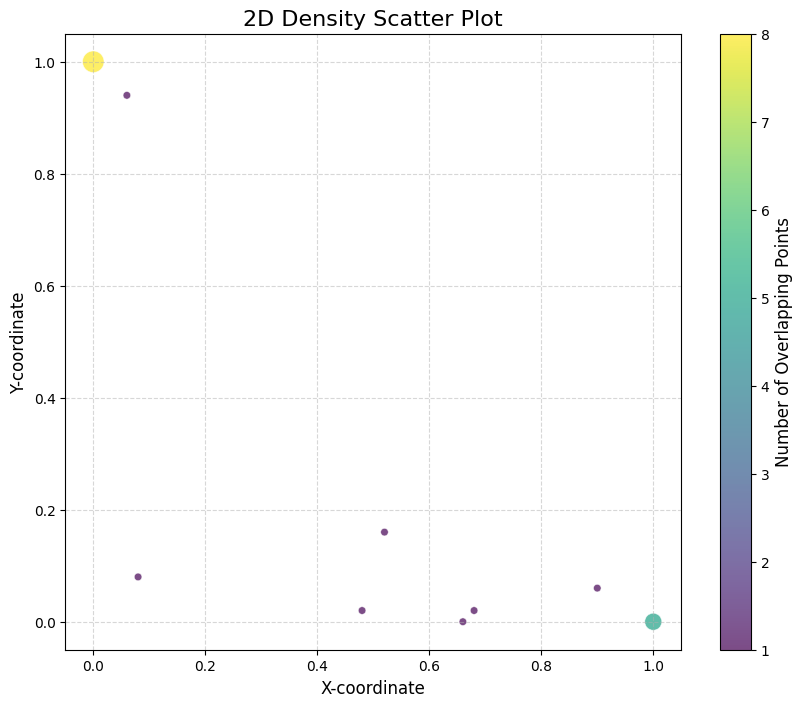

In [71]:
plot_density_dots(res)

In [65]:
summary_results

{'Memory answer': 0.0,
 'Counter answer 1': 1.0,
 'Counter answer 2': 0.0,
 'Distractor answer': 0.0}

In [66]:
answers

['Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records']

1. create 100 samples entity based and 100 samples num/date based - **Done**
2. create distractor paragraphs (for each answer) - **Done**
3. sanity check #1 - ask llm based on memory alone
4. ask with 1 reasoning path and compare between 2 groups (graph will be prob to answer context (softmax with memory, without invalids) vs reasoning chain length)
5. sanity check #2 - ask llm with disconnected reasoning chains
6. qualitive check of the good and bad samples
7. ask with 2 reasoning paths and compare between 2 groups

# analize:

In [10]:
import plotly.graph_objects as go

# Sample data
x1 = [1, 2, 3, 2, None]
x2 = [None, 2, 2, 3, 1]
y1 = [0.8, 0.5, 0.3, 0.2, 0.7]  # memory
y2 = [0.1, 0.4, 0.6, 0.7, 0.2]  # context 1
y3 = [0.1, 0.1, 0.1, 0.1, 0.1]  # context 2

# Convert None to -1 for plotting
x1 = [v if v is not None else -1 for v in x1]
x2 = [v if v is not None else -1 for v in x2]

fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=x1, y=x2, z=y1,
    mode='markers', name='Memory',
    marker=dict(size=6, color='red')
))
fig.add_trace(go.Scatter3d(
    x=x1, y=x2, z=y2,
    mode='markers', name='Context Answer 1',
    marker=dict(size=6, color='green')
))
fig.add_trace(go.Scatter3d(
    x=x1, y=x2, z=y3,
    mode='markers', name='Context Answer 2',
    marker=dict(size=6, color='blue')
))

fig.update_layout(
    scene=dict(
        xaxis_title='x1 (Hops for Context 1)',
        yaxis_title='x2 (Hops for Context 2)',
        zaxis_title='Probability'
    ),
    title='Answer Probability by Reasoning Path Setup',
    height=600,
    showlegend=True
)

fig.show()

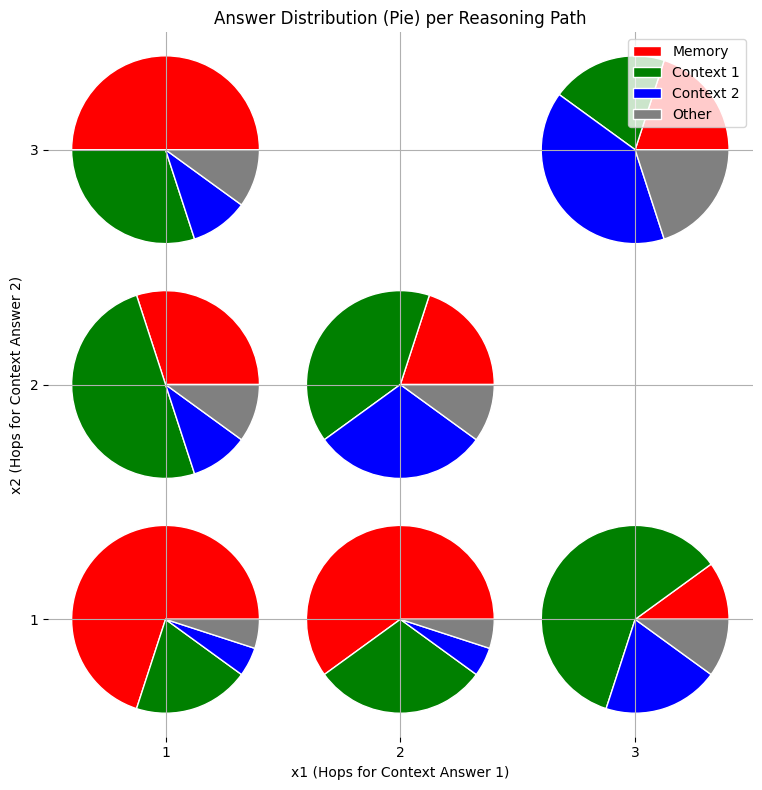

In [20]:
import matplotlib.pyplot as plt
%matplotlib inline

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# Simulated data: (x1, x2, [y1, y2, y3])
data = [
    (1, 1, [0.7, 0.2, 0.05]),   # Mostly memory
    (1, 2, [0.3, 0.5, 0.1]),    # Mostly context 1
    (2, 1, [0.6, 0.3, 0.05]),
    (2, 2, [0.2, 0.4, 0.3]),    # More balanced
    (3, 1, [0.1, 0.6, 0.2]),    # Mostly context 1
    (1, 3, [0.5, 0.3, 0.1]),
    (3, 3, [0.2, 0.2, 0.4]),    # Mostly context 2
]

colors = ['red', 'green', 'blue', 'gray']  # memory, context1, context2, other
pie_radius = 0.4

fig, ax = plt.subplots(figsize=(8, 8))

for x1, x2, probs in data:
    y1, y2, y3 = probs
    y4 = max(0, 1 - (y1 + y2 + y3))  # "Other" answer
    values = [y1, y2, y3, y4]

    # Draw a pie chart at (x1, x2)
    wedges, _ = ax.pie(
        values,
        colors=colors,
        radius=pie_radius,
        center=(x1, x2),
        wedgeprops=dict(width=pie_radius, edgecolor='w')
    )

# Grid setup
ax.set_aspect('equal')
ax.set_xticks(sorted(set(x[0] for x in data)))
ax.set_yticks(sorted(set(x[1] for x in data)))
ax.set_xlim(0.5, 3.5)
ax.set_ylim(0.5, 3.5)
ax.set_xlabel('x1 (Hops for Context Answer 1)')
ax.set_ylabel('x2 (Hops for Context Answer 2)')
ax.set_title('Answer Distribution (Pie) per Reasoning Path')

# Legend
legend_labels = ['Memory', 'Context 1', 'Context 2', 'Other']
legend_patches = [Patch(facecolor=c, edgecolor='w', label=l)
                  for c, l in zip(colors, legend_labels)]
ax.legend(handles=legend_patches, loc='upper right')

plt.grid(True)
plt.tight_layout()
plt.show()


# New Dev:

In [32]:
dev_context = """
Write This Down is a rock band formed in the mid-2000s in Minneapolis, Minnesota. Known for its post-hardcore style, the band gained popularity in the local music scene before signing to a national label. Minneapolis, one of the Twin Cities, lies along the banks of the Mississippi River and has long been a cultural and economic hub of the Upper Midwest.
\n\n
The Mississippi River is one of the major rivers of North America, flowing south from northern Minnesota to the Gulf of Mexico. It served as a critical natural boundary in early U.S. history. The river marked the western edge of the original territory ceded to the United States following the American Revolutionary War.
\n\n
The Treaty of Colombia, signed in 1783, formally ended the Revolutionary War between Great Britain and the thirteen American colonies. As part of the agreement, Great Britain recognized American independence and ceded vast territories to the new nation, extending its western boundary to the Mississippi River.
"""
dev_context1 = """
Write This Down is a rock band formed in the mid-2000s in Minneapolis, Minnesota. Known for its post-hardcore style, the band gained popularity in the local music scene before signing to a national label. Minneapolis, one of the Twin Cities, lies along the banks of the Mississippi River and has long been a cultural and economic hub of the Upper Midwest.
"""
dev_question = "What treaty ceded territory to the US extending west to the body of water by the city where Write This Down was formed?"

prompt = f"""
    You are a logical reasoner. Your task is to answer the question using only the information found in the context below.

    Rules:
    - Do NOT use any external or real-world knowledge.
    - Only rely on statements explicitly made in the context, even if they are factually incorrect.
    - If the context contains contradictions, choose the answer that is best supported by the majority of consistent clues.
    - Your answer must be a single entity or phrase clearly supported by the context.

    Context:
    {dev_context1}

    Question:
    {dev_question}
    """

In [33]:
from knowledge_maze.tools.api_tools import gptAPI
import nest_asyncio
nest_asyncio.apply()

model = gptAPI(prompt,
                  output_format='string',
                  temperature = 1.5,
                  max_concurrent_requests = 100,
                  max_rpm=4900)

answer = model.run('')

In [34]:
answer

'Treaty of Paris 1763'

- try to write explicitly that the answer is **not** the memory answer.
- stirring the model to avoid a certain concept (kfir will send me more info)